<a href="https://colab.research.google.com/github/SUZAN1010/Formative-Assignment-for-502AZ/blob/main/502AZ_Task_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import pandas as pd  # Imports pandas for reading and inspecting tabular data.

bike = pd.read_csv("/content/train (1).csv")  # Loads the labelled bike rental CSV into a DataFrame.
print("Bike Sharing shape:", bike.shape)  # Prints the number of rows and columns.
display(bike.head())  # Displays the first five rows.

Bike Sharing shape: (10886, 12)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [5]:
print(bike.isna().sum())  # Counts missing values in each column.

zero_wind = bike["windspeed"].eq(0)  # Marks rows with a recorded windspeed of zero.
print("Zero windspeed rows:", zero_wind.sum())  # Counts the marked rows.

zero_by_weather = zero_wind.groupby(bike["weather"]).mean() * 100  # Calculates the percentage of zero readings in each weather category.
print(zero_by_weather.round(2))  # Displays the percentages to two decimal places.

rental_total = bike["casual"] + bike["registered"]  # Adds the two types of rentals for each hour.
print("Does the sum always equal count?", rental_total.eq(bike["count"]).all())  # Checks whether the sum reveals the prediction target.

datetime      0
season        0
holiday       0
workingday    0
weather       0
temp          0
atemp         0
humidity      0
windspeed     0
casual        0
registered    0
count         0
dtype: int64
Zero windspeed rows: 1313
weather
1    12.53
2    11.93
3     8.61
4     0.00
Name: windspeed, dtype: float64
Does the sum always equal count? True


The dataset contained no missing entries. Windspeed was recorded as zero in 1,313 rows (12.06%). The percentage varied by weather category, but this check could not determine whether the zeros represented calm conditions or missing readings. The recorded zeros were retained for the initial model comparison. casual and registered were excluded as predictors because their sum reveals the target count.

In [6]:
bike["datetime"] = pd.to_datetime(bike["datetime"])  # Converts date strings to timestamps.
bike = bike.sort_values("datetime").reset_index(drop=True)  # Orders records from earliest to latest.
bike["hour"] = bike["datetime"].dt.hour  # Extracts the hour of the day from each timestamp.

categorical = ["season", "holiday", "workingday", "weather", "hour"]  # Lists the features to one-hot encode.
numerical = ["temp", "atemp", "humidity", "windspeed"]  # Lists the numerical measurements.

X = bike[categorical + numerical]  # Selects the predictors and excludes the two rental components.
y = bike["count"]  # Selects the total rentals as the prediction target.

split = int(len(bike) * 0.8)  # Finds where the first 80% of rows ends.
X_train, X_test = X.iloc[:split], X.iloc[split:]  # Uses earlier inputs for training and later inputs for testing.
y_train, y_test = y.iloc[:split], y.iloc[split:]  # Splits rental counts at the same position.

print("Training rows:", len(X_train))  # Reports the number of training records.
print("Test rows:", len(X_test))  # Reports the number of held-out records.
print("Last training time:", bike.loc[split - 1, "datetime"])  # Shows the end of the training period.
print("First test time:", bike.loc[split, "datetime"])  # Shows the start of the test period.

Training rows: 8708
Test rows: 2178
Last training time: 2012-08-05 04:00:00
First test time: 2012-08-05 05:00:00


In [7]:
from sklearn.compose import ColumnTransformer  # Applies different transformations to different columns.
from sklearn.ensemble import RandomForestRegressor  # Imports the model that combines multiple decision trees.
from sklearn.linear_model import LinearRegression  # Imports the baseline regression model.
from sklearn.metrics import mean_absolute_error, mean_squared_error  # Imports two measures of prediction error.
from sklearn.pipeline import make_pipeline  # Combines preprocessing and model training.
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # Encodes categories and scales numerical inputs.

models = {
    "Linear Regression": LinearRegression(),  # Provides a simple baseline for comparison.
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1  # Builds 100 trees with a fixed seed.
    )
}

results = []  # Stores one score row per model.

for name, model in models.items():  # Trains and evaluates each model on the same split.
    preprocess = ColumnTransformer([  # Creates a fresh preprocessing setup for each model.
        ("categories", OneHotEncoder(handle_unknown="ignore"), categorical),  # Creates category indicators.
        ("numbers", StandardScaler(), numerical)  # Scales numerical features using training statistics.
    ])
    pipeline = make_pipeline(preprocess, model)  # Applies preprocessing before the model.
    pipeline.fit(X_train, y_train)  # Fits both steps using only the earlier records.
    predictions = pipeline.predict(X_test)  # Predicts rental counts for the held-out period.

    results.append({
        "Model": name,  # Records the model name.
        "MAE": mean_absolute_error(y_test, predictions),  # Calculates the average absolute error.
        "RMSE": mean_squared_error(y_test, predictions) ** 0.5  # Gives larger errors more weight.
    })

bike_scores = pd.DataFrame(results).sort_values("RMSE")  # Ranks the models by lowest RMSE.
display(bike_scores.round(2))  # Displays the two models' scores to two decimal places.

,Model,MAE,RMSE
1,Random Forest,87.30,125.09
0,Linear Regression,111.38,158.45


Random Forest performed better on the same 2,178 test records. Its RMSE was 125.09 bikes per hour, compared with 158.45 for Linear Regression. Its MAE was also lower, at 87.30 compared with 111.38. RMSE gives more weight to large prediction errors.

In [10]:
import pandas as pd  # Imports pandas for reading tabular data.

shop = pd.read_csv(
    "/content/data.csv (2).zip",  # Points to the uploaded E-Commerce archive.
    compression="zip",  # Reads the CSV inside the archive.
    encoding="latin1"  # Decodes the CSV text.
)

print("E-Commerce shape:", shop.shape)  # Displays the number of rows and columns.

E-Commerce shape: (541909, 8)


In [11]:
missing_customer_id = shop["CustomerID"].isna()  # Flags rows with a missing customer ID.
cancelled_invoice = shop["InvoiceNo"].astype("string").str.startswith("C", na=False)  # Flags cancellation rows.

print("Raw dataset shape:", shop.shape)  # Reports the size before cleaning.
print("Rows with missing customer ID:", missing_customer_id.sum())  # Counts rows without an assigned customer.
print("Rows on cancelled invoices:", cancelled_invoice.sum())  # Counts transaction lines on cancelled invoices.
display(shop[["Quantity", "UnitPrice"]].describe().round(2))  # Summarises raw quantities and prices.

Raw dataset shape: (541909, 8)
Rows with missing customer ID: 135080
Rows on cancelled invoices: 9288


,Quantity,UnitPrice
count,541909.00,541909.00
mean,9.55,4.61
std,218.08,96.76
min,-80995.00,-11062.06
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
max,80995.00,38970.00


In [12]:
positive_purchase = shop["Quantity"].gt(0) & shop["UnitPrice"].gt(0)  # Flags lines with positive quantity and price.
keep = ~missing_customer_id & ~cancelled_invoice & positive_purchase  # Selects identified purchases with positive values.
sales = shop.loc[keep].copy()  # Copies the retained rows for customer-level analysis.

sales["InvoiceDate"] = pd.to_datetime(  # Converts the CSV dates to timestamps.
    sales["InvoiceDate"], format="%m/%d/%Y %H:%M", errors="coerce"  # Uses month/day/year and marks invalid dates as missing.
)
sales = sales.dropna(subset=["InvoiceDate", "InvoiceNo"])  # Removes rows missing a valid date or invoice number.
sales["LineSpend"] = sales["Quantity"] * sales["UnitPrice"]  # Calculates spending for each retained line.

reference_date = sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)  # Sets the reference to the day after the latest purchase.

rfm = sales.groupby("CustomerID").agg(  # Creates one row per customer.
    LastPurchase=("InvoiceDate", "max"),  # Finds each customer's most recent purchase.
    Frequency=("InvoiceNo", "nunique"),  # Counts distinct invoices so multi-item orders are counted once.
    Spend=("LineSpend", "sum")  # Totals the value of retained purchase lines.
)
rfm["Recency"] = (reference_date - rfm["LastPurchase"].dt.normalize()).dt.days  # Calculates days since the last purchase.
rfm = rfm[["Recency", "Frequency", "Spend"]]  # Keeps the three features for clustering.

print("Retained transaction rows:", len(sales))  # Reports the cleaned transaction count.
print("Excluded transaction rows:", len(shop) - len(sales))  # Counts each removed row once.
print("Recency reference date:", reference_date.date())  # Shows the date used to calculate recency.
print("Customer table shape:", rfm.shape)  # Reports the number of customers and features.
display(rfm.describe().round(2))  # Summarises recency, frequency and spend across customers.

Retained transaction rows: 397884
Excluded transaction rows: 144025
Recency reference date: 2011-12-10
Customer table shape: (4338, 3)


,Recency,Frequency,Spend
count,4338.00,4338.00,4338.00
mean,93.06,4.27,2054.27
std,100.01,7.70,8989.23
min,1.00,1.00,3.75
25%,18.00,1.00,307.41
50%,51.00,2.00,674.48
75%,142.75,5.00,1661.74
max,374.00,209.00,280206.02


In [13]:
import numpy as np  # Provides the log transformation.
from sklearn.cluster import AgglomerativeClustering, KMeans  # Imports both clustering methods.
from sklearn.metrics import silhouette_score  # Imports the cluster separation metric.
from sklearn.preprocessing import StandardScaler  # Imports the feature scaler.

prepared = rfm.copy()  # Preserves recency, frequency and spend in their original units.
prepared[["Frequency", "Spend"]] = np.log1p(prepared[["Frequency", "Spend"]])  # Compresses large values.

skew_comparison = pd.DataFrame({
    "Before": rfm.skew(),  # Measures skewness in the original customer features.
    "After": prepared.skew()  # Measures skewness after transforming frequency and spend.
})
display(skew_comparison.round(2))  # Shows whether skewness moved closer to zero.

customer_features = StandardScaler().fit_transform(prepared)  # Puts all three features on comparable scales.

cluster_results = []  # Stores one score per method and cluster count.
cluster_labels = {}  # Stores customer assignments for later interpretation.

for k in range(2, 7):  # Tests two through six clusters.
    methods = {
        "K-Means": KMeans(n_clusters=k, n_init=10, random_state=42),  # Uses ten reproducible starting configurations.
        "Agglomerative (Ward)": AgglomerativeClustering(n_clusters=k, linkage="ward")  # Merges groups using Ward linkage.
    }

    for method, model in methods.items():  # Fits both methods on the same prepared features.
        labels = model.fit_predict(customer_features)  # Assigns each customer to a cluster.
        cluster_labels[(method, k)] = labels  # Saves the assignments for this run.
        cluster_results.append({
            "Method": method,  # Records the algorithm.
            "Clusters": k,  # Records the number of clusters.
            "Silhouette": silhouette_score(customer_features, labels)  # Measures how well the clusters are separated.
        })

cluster_scores = pd.DataFrame(cluster_results).sort_values("Silhouette", ascending=False)  # Ranks all ten runs.
display(cluster_scores.round(3))  # Displays the scores to three decimal places.

,Before,After
Recency,1.25,1.25
Frequency,12.07,1.21
Spend,19.32,0.39


,Method,Clusters,Silhouette
2,K-Means,3,0.416
0,K-Means,2,0.406
1,Agglomerative (Ward),2,0.394
4,K-Means,4,0.380
3,Agglomerative (Ward),3,0.371
5,Agglomerative (Ward),4,0.345
6,K-Means,5,0.343
8,K-Means,6,0.330
7,Agglomerative (Ward),5,0.300
9,Agglomerative (Ward),6,0.260


,Customers,MedianRecency,MedianFrequency,MedianSpend
Cluster,,,,
0,2033,46.0,2.0,508.81
1,1325,18.0,7.0,2575.00
2,980,253.0,1.0,291.76


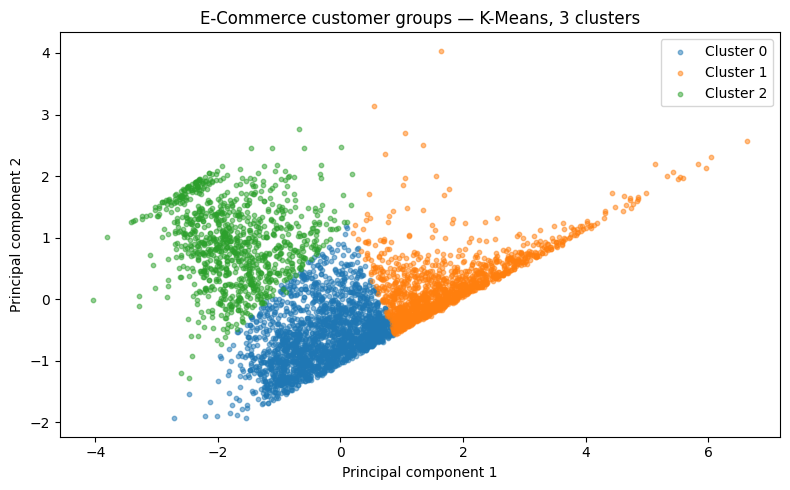

In [14]:
import matplotlib.pyplot as plt  # Imports plotting functions.
from sklearn.decomposition import PCA  # Imports the method used to display the features on two axes.

labels = cluster_labels[("K-Means", 3)]  # Retrieves the customer labels from the highest-scoring run.

profile = rfm.assign(Cluster=labels).groupby("Cluster").agg(
    Customers=("Recency", "size"),  # Counts the customers in each cluster.
    MedianRecency=("Recency", "median"),  # Finds the median days since the last purchase.
    MedianFrequency=("Frequency", "median"),  # Finds the median number of distinct invoices.
    MedianSpend=("Spend", "median"),  # Finds the median spend in the original currency.
)
display(profile.round(2))  # Displays the three profiles in their original units.

points = PCA(n_components=2).fit_transform(customer_features)  # Projects the scaled features onto two axes.
plt.figure(figsize=(8, 5))  # Creates the plot.

for cluster in profile.index:  # Plots one cluster at a time.
    mask = labels == cluster  # Selects customers assigned to this cluster.
    plt.scatter(points[mask, 0], points[mask, 1], s=10, alpha=0.5,
                label=f"Cluster {cluster}")  # Adds one point per customer.

plt.xlabel("Principal component 1")  # Labels the horizontal axis.
plt.ylabel("Principal component 2")  # Labels the vertical axis.
plt.title("E-Commerce customer groups — K-Means, 3 clusters")  # Identifies the model and cluster count.
plt.legend()  # Identifies each cluster by colour.
plt.tight_layout()  # Adjusts the spacing around the plot.
plt.show()  # Displays the plot.

K-Means with three clusters had the highest silhouette score among the runs tested (0.416). Cluster 1 contained 1,325 customers and had the most recent purchases, with a median recency of 18 days. It also had the highest median frequency (7 orders) and spend (£2,575). Cluster 2 contained 980 customers and had the longest time since purchase (253 days), with a median of one order. Cluster 0 was the largest group (2,033 customers) and fell between the other two on all three measures.